In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectFromModel

import xgboost
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

In [18]:
# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Select relevant features and drop rows with missing values
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
df.dropna(inplace=True)

In [19]:
# Encode categorical variables
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
df['Embarked'] = LabelEncoder().fit_transform(df['Embarked'])
X = df.drop('Survived', axis=1)
y = df['Survived']
feature_names = X.columns

In [20]:
# Feature Importance dựa vào thuật toán Random Forest

rf_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(X, y)

importances = rf_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

print("Embedded Method - Feature Importance:")
print(feat_imp)

Embedded Method - Feature Importance:
Age         0.281662
Sex         0.252257
Fare        0.246379
Pclass      0.101578
SibSp       0.047823
Parch       0.042208
Embarked    0.028093
dtype: float64


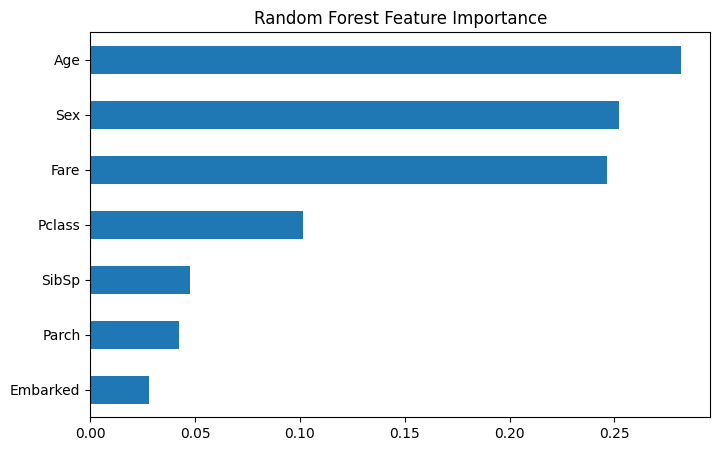

In [21]:
# Vẽ biểu đồ các thuộc tính
feat_imp.plot(kind='barh', title='Random Forest Feature Importance', figsize=(8, 5))
plt.gca().invert_yaxis()
plt.show()

In [22]:
# Hiển thị 3 thuộc tính có chỉ số lớn nhất
feat_imp.nlargest(3)

,0
Age,0.281662
Sex,0.252257
Fare,0.246379


In [23]:
# Feature Importance dựa vào thuật toán XGBoost Classifier

xgb_model = xgboost.XGBClassifier()
xgb_model.fit(X,y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [24]:
importances = xgb_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

print("Embedded Method - Feature Importance:")
print(feat_imp)

Embedded Method - Feature Importance:
Sex         0.558827
Pclass      0.233604
SibSp       0.078760
Age         0.036907
Parch       0.034872
Fare        0.029406
Embarked    0.027626
dtype: float32


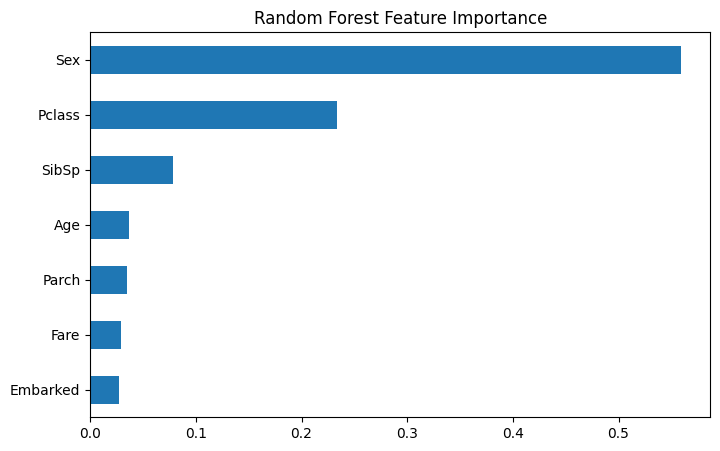

In [25]:
# Vẽ biểu đồ các thuộc tính
feat_imp.plot(kind='barh', title='Random Forest Feature Importance', figsize=(8, 5))
plt.gca().invert_yaxis()
plt.show()

In [26]:
# Hiển thị 3 thuộc tính có chỉ số lớn nhất
feat_imp.nlargest(3)

,0
Sex,0.558827
Pclass,0.233604
SibSp,0.078760
